# Superstore sales analysis (2014–2017)

**Question:** where does the business make and lose money, and what should change?

**Key findings**

1. Revenue grew **51%** from 2014 to 2017. Technology leads in both revenue ($836K) and profit ($145K).
2. **Furniture** is the #2 category by revenue ($742K) but earns only a **2.5% margin**, against 17% for the other two categories.
3. The cause is **deep discounting**. Furniture deals discounted more than 20% make up 26% of the category's revenue and lost **$54K**, three times the category's entire profit. The losses concentrate in Tables and Bookcases and in four states (Texas, Illinois, Pennsylvania, Ohio).
4. Discounts are not linked to larger orders: units per order line are the same with and without a discount (Spearman ρ ≈ 0).

**Recommendation:** cap Furniture discounts at 20%, starting with Tables and Bookcases, and review the blanket discounts in TX, IL, PA and OH. On historical data, Furniture's margin without the deeper-discounted deals is 13.3%. Because discounts might still bring in orders that would not happen otherwise, roll the cap out as an A/B test by state.

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
FIG_DIR = Path('../data')

# Chart style: light surface, hairline grid, blue for the main series, red only for losses
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, RED, GRAY = '#2a78d6', '#eb6834', '#e34948', '#b4b2a9'
mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})
DIVERGING = LinearSegmentedColormap.from_list('red_gray_blue', [RED, '#f0efec', BLUE])
money = mpl.ticker.FuncFormatter(lambda v, _: f'${v / 1000:,.0f}K')

def usd(v):
    return f'-${-v:,.0f}' if v < 0 else f'${v:,.0f}'

In [2]:
df = pd.read_csv('../data/superstore.csv', encoding='latin-1')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month

assert df.isna().sum().sum() == 0 and not df.duplicated().any()
print(f"{len(df):,} order lines, {df['Order ID'].nunique():,} orders, {df['Customer ID'].nunique()} customers, "
      f"{df['Order Date'].min():%b %Y} – {df['Order Date'].max():%b %Y}")
print(f"Revenue ${df['Sales'].sum():,.0f}, profit ${df['Profit'].sum():,.0f}, "
      f"margin {df['Profit'].sum() / df['Sales'].sum():.1%}")

9,994 order lines, 5,009 orders, 793 customers, Jan 2014 – Dec 2017
Revenue $2,297,201, profit $286,397, margin 12.5%


## 1. Categories: Furniture sells but barely earns

Margin here is always **total profit ÷ total revenue** of a group. Averaging per-line margins instead would let a $2 line weigh as much as a $2,000 one.

In [3]:
def summarize(frame, by):
    out = frame.groupby(by, observed=True)[['Sales', 'Profit']].sum()
    out['Margin'] = out['Profit'] / out['Sales']
    return out

category = summarize(df, 'Category').sort_values('Sales', ascending=False)
category.style.format({'Sales': '${:,.0f}', 'Profit': '${:,.0f}', 'Margin': '{:.1%}'})

,Sales,Profit,Margin
Category,,,
Technology,"$836,154","$145,455",17.4%
Furniture,"$742,000","$18,451",2.5%
Office Supplies,"$719,047","$122,491",17.0%


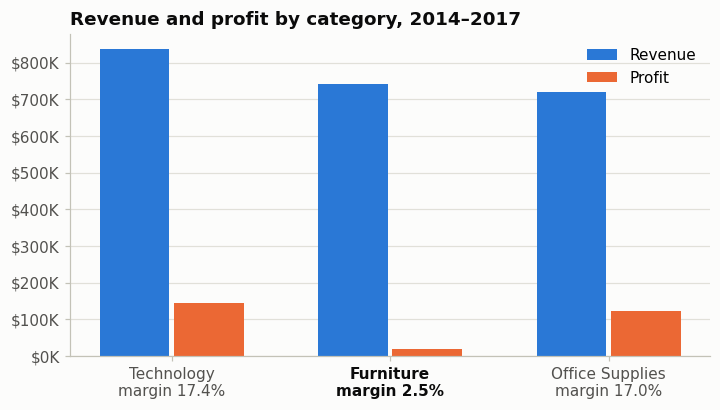

In [4]:
x = np.arange(len(category))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(x - 0.17, category['Sales'], width=0.32, color=BLUE, label='Revenue')
ax.bar(x + 0.17, category['Profit'], width=0.32, color=ORANGE, label='Profit')
ax.set_xticks(x, [f"{name}\nmargin {m:.1%}" for name, m in category['Margin'].items()])
for tick, name in zip(ax.get_xticklabels(), category.index):
    if name == 'Furniture':
        tick.set_fontweight('semibold'); tick.set_color(INK)
ax.yaxis.set_major_formatter(money)
ax.set_title('Revenue and profit by category, 2014–2017')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
fig.savefig(FIG_DIR / 'category_revenue_profit.png')
plt.show()

## 2. Growth and seasonality

In [5]:
yearly = df.groupby('Year')['Sales'].sum()
growth = yearly.iloc[-1] / yearly.iloc[0] - 1
print(f'Revenue {yearly.index[0]}: ${yearly.iloc[0]:,.0f} → {yearly.index[-1]}: ${yearly.iloc[-1]:,.0f} ({growth:+.0%})')
print('Year over year:', (yearly.pct_change().dropna() * 100).round(1).to_dict())

monthly = df.pivot_table(index='Year', columns='Month', values='Sales', aggfunc='sum')
peak_months = sorted({m for year in monthly.index for m in monthly.loc[year].nlargest(3).index})
share = df.loc[df['Month'].isin(peak_months), 'Sales'].sum() / df['Sales'].sum()
print(f'Top-3 months every year: {peak_months} → {share:.0%} of all revenue')

Revenue 2014: $484,247 → 2017: $733,215 (+51%)
Year over year: {2015: -2.8, 2016: 29.5, 2017: 20.4}
Top-3 months every year: [9, 11, 12] → 43% of all revenue


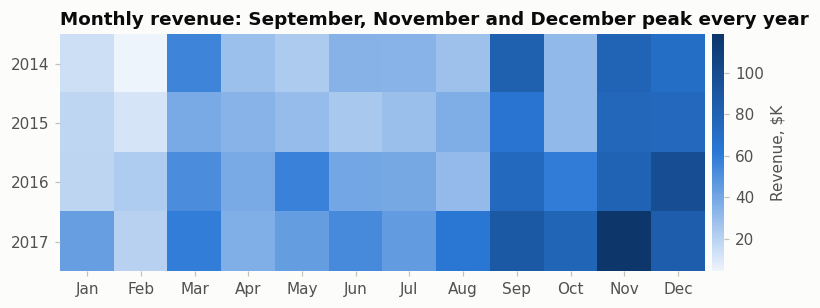

In [6]:
fig, ax = plt.subplots(figsize=(9, 2.8))
im = ax.imshow(monthly.values / 1000, cmap=LinearSegmentedColormap.from_list('blues', ['#eef4fc', '#2a78d6', '#0d366b']),
               aspect='auto')
ax.set_xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_yticks(range(len(monthly.index)), monthly.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label('Revenue, $K', color=INK2)
cbar.outline.set_visible(False)
ax.set_title('Monthly revenue: September, November and December peak every year')
fig.savefig(FIG_DIR / 'seasonality_heatmap.png')
plt.show()

## 3. Regions and cities

,Sales,Profit,Margin
Region,,,
West,"$725,458","$108,418",14.9%
East,"$678,781","$91,523",13.5%
Central,"$501,240","$39,706",7.9%
South,"$391,722","$46,749",11.9%


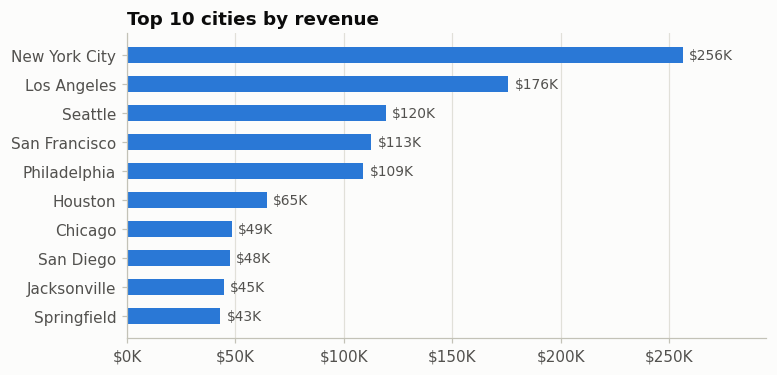

In [7]:
region = summarize(df, 'Region').sort_values('Sales', ascending=False)
cities = df.groupby('City')['Sales'].sum().nlargest(10)
display(region.style.format({'Sales': '${:,.0f}', 'Profit': '${:,.0f}', 'Margin': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(cities.index[::-1], cities.values[::-1], height=0.55, color=BLUE)
for i, v in enumerate(cities.values[::-1]):
    ax.annotate(f'${v / 1000:,.0f}K', (v, i), textcoords='offset points', xytext=(4, 0), va='center', color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(money)
ax.set_xlim(0, cities.max() * 1.15)
ax.grid(axis='y', visible=False)
ax.set_title('Top 10 cities by revenue')
plt.show()

## 4. Sub-categories: three lose money

Tables (−8.6%) and Bookcases (−3.0%), both Furniture, lose the most. Supplies also runs at a loss. (An earlier version of the README named Binders at −2.5%: that figure belongs to Supplies, while Binders earn a 14.9% margin.)

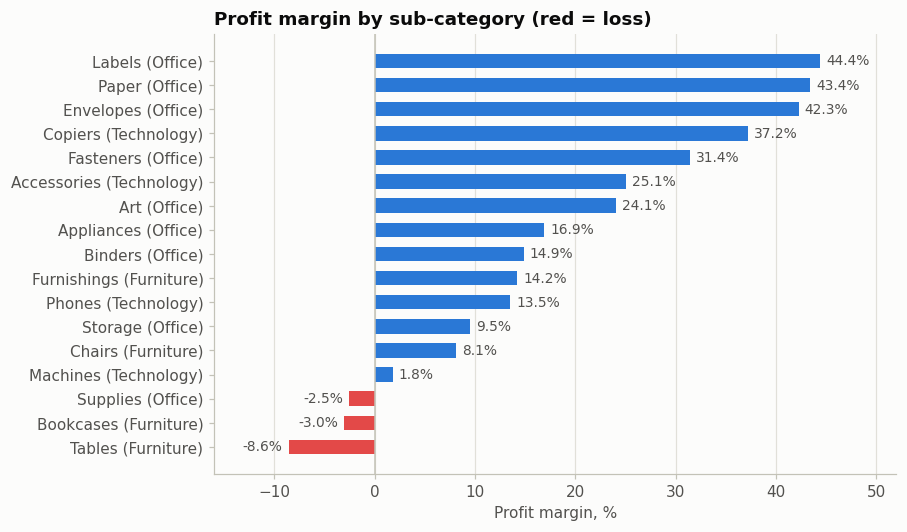

In [8]:
sub = summarize(df, ['Category', 'Sub-Category']).reset_index().sort_values('Margin')
labels = sub['Sub-Category'] + ' (' + sub['Category'].str.split().str[0] + ')'

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(labels, sub['Margin'] * 100, height=0.6, color=np.where(sub['Margin'] < 0, RED, BLUE))
for i, v in enumerate(sub['Margin'] * 100):
    ax.annotate(f'{v:.1f}%', (v, i), textcoords='offset points', xytext=(4 if v >= 0 else -4, 0),
                ha='left' if v >= 0 else 'right', va='center', color=INK2, fontsize=9)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlim(-16, 52)
ax.set_xlabel('Profit margin, %')
ax.grid(axis='y', visible=False)
ax.set_title('Profit margin by sub-category (red = loss)')
fig.savefig(FIG_DIR / 'subcategory_margin.png')
plt.show()

## 5. Root cause: discounts

Discounts in this data range from 0% to 80%. Grouping Furniture lines by discount level shows where the margin disappears.

In [9]:
bands = [-0.01, 0, 0.2, 0.3, 1.0]
band_labels = ['0%', '10–20%', '30%', 'over 30%']  # discount levels that occur: 0, 10–20, 30, 32–80%
df['Discount band'] = pd.cut(df['Discount'], bins=bands, labels=band_labels)
furniture = df[df['Category'] == 'Furniture']

by_band = summarize(furniture, 'Discount band')
by_band['Share of revenue'] = by_band['Sales'] / by_band['Sales'].sum()
by_band.style.format({'Sales': '${:,.0f}', 'Profit': '${:,.0f}', 'Margin': '{:.1%}', 'Share of revenue': '{:.0%}'})

,Sales,Profit,Margin,Share of revenue
Discount band,,,,
0%,"$256,025","$58,133",22.7%,35%
10–20%,"$290,824","$14,796",5.1%,39%
30%,"$99,470","$-10,695",-10.8%,13%
over 30%,"$95,680","$-43,782",-45.8%,13%


In [10]:
deep = furniture[furniture['Discount'] > 0.2]
rest = furniture[furniture['Discount'] <= 0.2]
print(f"Furniture deals discounted above 20%: {len(deep)} lines, {usd(deep['Sales'].sum())} revenue "
      f"({deep['Sales'].sum() / furniture['Sales'].sum():.0%} of Furniture), profit {usd(deep['Profit'].sum())}")
print(f"Furniture total profit: {usd(furniture['Profit'].sum())} "
      f"→ deep-discount losses are {-deep['Profit'].sum() / furniture['Profit'].sum():.1f}x the category's profit")
print(f"Furniture margin on the other deals: {rest['Profit'].sum() / rest['Sales'].sum():.1%} (vs 2.5% overall)")
loss_by_sub = deep.groupby('Sub-Category')['Profit'].sum().sort_values()
print('Deep-discount losses by sub-category:', ', '.join(f'{k} {usd(v)}' for k, v in loss_by_sub.items()))

Furniture deals discounted above 20%: 542 lines, $195,151 revenue (26% of Furniture), profit -$54,478
Furniture total profit: $18,451 → deep-discount losses are 3.0x the category's profit
Furniture margin on the other deals: 13.3% (vs 2.5% overall)
Deep-discount losses by sub-category: Tables -$30,698, Bookcases -$11,098, Chairs -$6,737, Furnishings -$5,945


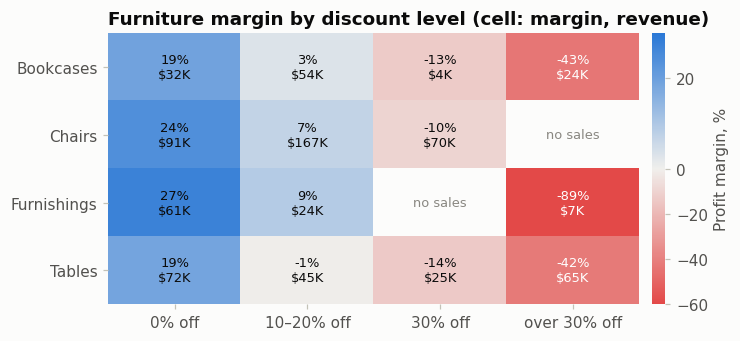

In [11]:
pivot = (furniture.pivot_table(index='Sub-Category', columns='Discount band', values='Profit', aggfunc='sum', observed=False)
         / furniture.pivot_table(index='Sub-Category', columns='Discount band', values='Sales', aggfunc='sum', observed=False) * 100)
revenue = furniture.pivot_table(index='Sub-Category', columns='Discount band', values='Sales', aggfunc='sum', observed=False)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(pivot.values, cmap=DIVERGING, norm=TwoSlopeNorm(vmin=-60, vcenter=0, vmax=30), aspect='auto')
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v, r = pivot.iat[i, j], revenue.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f'{v:.0f}%\n${r / 1000:,.0f}K', ha='center', va='center', fontsize=8.5,
                    color='white' if abs(v) > 35 else INK)
        else:
            ax.text(j, i, 'no sales', ha='center', va='center', fontsize=8.5, color=MUTED)
ax.set_xticks(range(pivot.shape[1]), [f'{c} off' for c in pivot.columns])
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Profit margin, %', color=INK2)
cbar.outline.set_visible(False)
ax.set_title('Furniture margin by discount level (cell: margin, revenue)')
fig.savefig(FIG_DIR / 'furniture_discount_heatmap.png')
plt.show()

Every Furniture sub-category is profitable without a discount (18–27%) and loses money beyond 20%. Where are those deep discounts given?

In [12]:
state = summarize(furniture, 'State')
state['Deep-discount share'] = (furniture[furniture['Discount'] > 0.2].groupby('State')['Sales'].sum()
                                / state['Sales']).fillna(0)
worst = state.sort_values('Profit').head(6)
worst.style.format({'Sales': '${:,.0f}', 'Profit': '${:,.0f}', 'Margin': '{:.1%}', 'Deep-discount share': '{:.0%}'})

,Sales,Profit,Margin,Deep-discount share
State,,,,
Texas,"$60,593","$-10,436",-17.2%,100%
Illinois,"$28,275","$-9,076",-32.1%,100%
Pennsylvania,"$39,355","$-7,197",-18.3%,81%
Ohio,"$24,199","$-4,206",-17.4%,83%
North Carolina,"$15,155","$-3,486",-23.0%,64%
Arizona,"$13,525","$-2,745",-20.3%,33%


In [13]:
top4 = worst.index[:4]
print(f"{', '.join(top4)}: {usd(worst.loc[top4, 'Profit'].sum())} Furniture profit combined; "
      f"in Texas and Illinois every Furniture sale carried a discount above 20%.")

Texas, Illinois, Pennsylvania, Ohio: -$30,915 Furniture profit combined; in Texas and Illinois every Furniture sale carried a discount above 20%.


## 6. Statistical checks

**Do discounts sell more units?** If they did, capping them could cost volume. Units per order line are compared across discount levels with a rank correlation and a Mann–Whitney U test (quantities are small integers, not normally distributed).

**Is the margin gap robust?** Lines of one order are not independent, so the 95% confidence interval for the margin gap is computed with a bootstrap that resamples whole orders.

In [14]:
rho, p_rho = stats.spearmanr(furniture['Discount'], furniture['Quantity'])
u = stats.mannwhitneyu(deep['Quantity'], rest['Quantity'])
print(f"Furniture: Spearman ρ(discount, units) = {rho:+.3f} (p = {p_rho:.2f})")
print(f"Mean units per line: deep discount {deep['Quantity'].mean():.2f} vs other {rest['Quantity'].mean():.2f} "
      f"(Mann–Whitney p = {u.pvalue:.2f})")
rho_all, p_all = stats.spearmanr(df['Discount'], df['Quantity'])
print(f"All categories: Spearman ρ = {rho_all:+.3f} (p = {p_all:.2f})")

Furniture: Spearman ρ(discount, units) = -0.007 (p = 0.74)
Mean units per line: deep discount 3.80 vs other 3.78 (Mann–Whitney p = 0.48)
All categories: Spearman ρ = -0.001 (p = 0.93)


In [15]:
rng = np.random.default_rng(42)
order_index = furniture.groupby('Order ID').indices
orders = np.array(list(order_index))
profit, sales = furniture['Profit'].to_numpy(), furniture['Sales'].to_numpy()
is_deep = (furniture['Discount'] > 0.2).to_numpy()

def margin_gap(rows):
    d = is_deep[rows]
    return profit[rows][~d].sum() / sales[rows][~d].sum() - profit[rows][d].sum() / sales[rows][d].sum()

gaps = [margin_gap(np.concatenate([order_index[o] for o in rng.choice(orders, size=len(orders))]))
        for _ in range(2000)]
low, high = np.percentile(gaps, [2.5, 97.5])
print(f'Margin gap (≤20% vs >20% discount): {margin_gap(np.arange(len(furniture))) * 100:.1f} pp, '
      f'95% CI [{low * 100:.1f}, {high * 100:.1f}] ({len(orders):,} orders resampled 2,000 times)')

Margin gap (≤20% vs >20% discount): 41.3 pp, 95% CI [38.2, 44.4] (1,764 orders resampled 2,000 times)


Units per line do not move with the discount, and the margin gap is about 41 percentage points with a tight interval.

## 7. Recommendation

- **Cap Furniture discounts at 20%**, starting with Tables and Bookcases, where deep discounts are most common.
- **Review the state-level discount policy** in Texas, Illinois, Pennsylvania and Ohio.
- **Test before rolling out.** The data shows discounts do not raise units per order line, but it cannot show whether they bring in orders that would not happen otherwise. Apply the cap in a random half of the affected states for one quarter and compare orders, revenue and profit with the other half.

On historical data, Furniture's margin on deals discounted 20% or less is 13.3%, against 2.5% overall. That number assumes the deeper-discounted deals would simply disappear, which is why the test comes first.